<a href="https://colab.research.google.com/github/thc1006/federated-5g-slice-optimization/blob/main/%5B%E8%81%AF%E9%82%A6%E5%AD%B8%E7%BF%92%5D_%E7%B6%B2%E8%B7%AF%E5%88%87%E7%89%87%E8%B3%87%E6%BA%90%E5%8B%95%E6%85%8B%E5%88%86%E9%85%8D%E6%9C%80%E4%BD%B3%E5%8C%96_v1_1_0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# @title Cell 4｜聯邦學習環境設置（徹底解決 GPU 問題版）
import os
import subprocess
import sys
import warnings
import importlib

warnings.filterwarnings("ignore")

print("🔬 深入診斷 GPU 環境問題...")
print("="*60)

# =========================================================
# 步驟 1: 詳細環境診斷
# =========================================================
def deep_diagnostic():
    """深入診斷 GPU 和 CUDA 環境"""
    print("📊 系統環境診斷：")

    # 1. 檢查 nvidia-smi
    try:
        gpu_info = subprocess.run(['nvidia-smi'], capture_output=True, text=True, check=True)
        print("✅ NVIDIA 驅動程式正常")
        # 解析 CUDA 版本
        for line in gpu_info.stdout.split('\n'):
            if 'CUDA Version' in line:
                cuda_version = line.split('CUDA Version:')[1].strip().split()[0]
                print(f"📌 CUDA 驅動版本: {cuda_version}")
                break
    except (subprocess.CalledProcessError, FileNotFoundError):
        print("❌ NVIDIA 驅動程式 (nvidia-smi) 未找到或執行失敗。")

    # 2. 檢查 CUDA 工具包
    try:
        nvcc_info = subprocess.run(['nvcc', '--version'], capture_output=True, text=True, check=True)
        print("✅ CUDA 編譯器 (nvcc) 存在")
        # 提取版本資訊行
        for line in nvcc_info.stdout.split('\n'):
            if 'release' in line:
                print(line)
                break
    except (subprocess.CalledProcessError, FileNotFoundError):
        print("⚠️ CUDA 編譯器 (nvcc) 未找到")

    # 3. 檢查已安裝的 TensorFlow
    try:
        import tensorflow as tf
        print(f"\n⚠️ 已存在 TensorFlow {tf.__version__}")
        print(f"   編譯 CUDA 支援: {tf.test.is_built_with_cuda()}")
        print(f"   GPU 可用: {len(tf.config.list_physical_devices('GPU')) > 0}")
    except ImportError:
        print("✅ 沒有預安裝的 TensorFlow")

    # 4. 檢查 LD_LIBRARY_PATH
    print(f"\n📁 LD_LIBRARY_PATH: {os.environ.get('LD_LIBRARY_PATH', '未設定')}")

    # 5. 列出 CUDA 相關檔案
    cuda_paths = [
        "/usr/local/cuda",
        "/usr/local/cuda-12.4",
        "/usr/local/cuda-12.2",
        "/usr/local/cuda-11.8"
    ]
    print("\n📁 CUDA 安裝路徑檢查:")
    for path in cuda_paths:
        if os.path.exists(path):
            print(f"   ✅ {path} 存在")
        else:
            print(f"   ❌ {path} 不存在")

deep_diagnostic()

# =========================================================
# 步驟 2: 完全清理環境
# =========================================================
print("\n" + "="*60)
print("🧹 執行深度清理...")

def nuclear_cleanup():
    """核彈級清理 - 移除所有可能衝突的套件"""

    # 完整的清理列表
    packages_to_nuke = [
        # TensorFlow 相關
        "tensorflow", "tensorflow-gpu", "tensorflow-cpu",
        "tensorflow-estimator", "tensorflow-probability",
        "tensorflow-federated", "tensorflow-privacy",
        "tensorflow-hub", "tensorflow-datasets",
        "tensorflow-metadata", "tensorflow-model-optimization",
        "tf-keras", "keras", "tensorboard",

        # JAX 相關
        "jax", "jaxlib", "flax", "optax",
        "jax-cuda12-plugin", "jax-cuda11-plugin",

        # CUDA 相關 pip 套件
        "nvidia-cuda-runtime-cu11", "nvidia-cuda-runtime-cu12",
        "nvidia-cudnn-cu11", "nvidia-cudnn-cu12",
        "nvidia-cublas-cu11", "nvidia-cublas-cu12",
        "nvidia-cuda-nvrtc-cu11", "nvidia-cuda-nvrtc-cu12",

        # 其他可能衝突的
        "triton", "torch", "cupy", "cupy-cuda11x", "cupy-cuda12x"
    ]

    print(f"🗑️ 準備移除 {len(packages_to_nuke)} 個可能的套件...")

    for i, pkg in enumerate(packages_to_nuke):
        if i > 0 and i % 5 == 0:
            print(f"   進度: {i}/{len(packages_to_nuke)}")
        # *** 修正點 ***
        # 移除 capture_output=True，並明確指定 stdout 和 stderr
        subprocess.run(
            [sys.executable, "-m", "pip", "uninstall", "-y", pkg],
            stdout=subprocess.DEVNULL,
            stderr=subprocess.DEVNULL,
            check=False
        )
    print(f"   進度: {len(packages_to_nuke)}/{len(packages_to_nuke)}")

    # 清理 pip 快取
    print("🗑️ 清理 pip 快取...")
    subprocess.run(
        [sys.executable, "-m", "pip", "cache", "purge"],
        stdout=subprocess.DEVNULL,
        stderr=subprocess.DEVNULL,
        check=False
    )

    print("✅ 深度清理完成")

nuclear_cleanup()

# =========================================================
# 步驟 3: 安裝正確版本的 TensorFlow
# =========================================================
print("\n" + "="*60)
print("🎯 安裝 CUDA 12.x 相容的 TensorFlow...")

def install_cuda12_tensorflow():
    """安裝 CUDA 12 相容的 TensorFlow"""

    # 設定環境變數
    print("⚙️ 設定環境變數...")
    os.environ['TF_CPP_MIN_LOG_LEVEL'] = '1' # 0=all, 1=info, 2=warning, 3=error
    os.environ['TF_FORCE_GPU_ALLOW_GROWTH'] = 'true'

    # 安裝基礎依賴
    print("\n📦 安裝基礎依賴...")
    base_deps = [
        "numpy<1.27", # 放寬版本限制，但避免最新的 2.x
        "protobuf<4.22,>=3.20",
        "packaging",
        "six",
        "wheel",
        "setuptools>=65.5.0"
    ]

    for dep in base_deps:
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "--no-deps", dep],
            stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL, check=False
        )

    # 方案 A: 嘗試安裝 TensorFlow 2.16（原生支援 CUDA 12）
    print("\n📦 方案 A: 嘗試安裝 TensorFlow 2.16.1...")
    result = subprocess.run(
        [
            sys.executable, "-m", "pip", "install",
            "--no-cache-dir", "--no-deps",
            "tensorflow==2.16.1"
        ],
        capture_output=True, text=True
    )

    if result.returncode != 0:
        print("   方案 A 失敗，嘗試方案 B...")
        # 方案 B: 使用 TensorFlow 2.15
        print("📦 方案 B: 安裝 TensorFlow 2.15.0...")
        subprocess.run(
            [
                sys.executable, "-m", "pip", "install",
                "--no-cache-dir", "--no-deps",
                "tensorflow==2.15.0"
            ],
            stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL, check=False
        )

    # 安裝 TensorFlow 的依賴
    print("\n📦 安裝 TensorFlow 相關依賴...")
    tf_deps = [
        "keras>=2.15,<2.17", # 根據 TF 版本調整
        "tensorboard>=2.15,<2.17",
        "tensorflow-estimator>=2.15,<2.17",
        "opt-einsum>=3.3.0",
        "astunparse>=1.6.3",
        "flatbuffers>=23.5.26",
        "gast>=0.4.0",
        "google-pasta>=0.2",
        "h5py>=3.10.0",
        "libclang>=13.0.0",
        "ml-dtypes>=0.2.0",
        "termcolor>=2.3.0",
        "typing-extensions>=4.5.0",
        "wrapt>=1.14.0"
    ]

    for dep in tf_deps:
        subprocess.run(
            [sys.executable, "-m", "pip", "install", dep],
            stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL, check=False
        )
    print("✅ TensorFlow 及其依賴安裝完成")


install_cuda12_tensorflow()

# =========================================================
# 步驟 4: 驗證 GPU 是否可用
# =========================================================
print("\n" + "="*60)
print("🔍 驗證 TensorFlow GPU 支援...")

def verify_gpu_support():
    """徹底驗證 GPU 支援"""
    try:
        # 重新載入 TensorFlow 以確保使用新安裝的版本
        if 'tensorflow' in sys.modules:
            importlib.reload(sys.modules['tensorflow'])

        import tensorflow as tf
        print(f"✅ TensorFlow {tf.__version__} 載入成功")

        # 詳細的 GPU 檢查
        print("\n📊 GPU 檢查:")
        print(f"   編譯時 CUDA 支援: {tf.test.is_built_with_cuda()}")

        # *** 修正點 ***
        # 使用推薦的 API 來檢查 GPU
        gpus = tf.config.list_physical_devices('GPU')
        print(f"   執行時偵測到 GPU 數量: {len(gpus)}")

        # 列出所有設備
        devices = tf.config.list_physical_devices()
        print(f"\n� 偵測到的所有實體設備 ({len(devices)} 個):")
        for device in devices:
            print(f"   - {device}")

        if gpus:
            print(f"\n🎮 找到 {len(gpus)} 個 GPU!")
            for i, gpu in enumerate(gpus):
                # 記憶體增長設定已在環境變數中設定，此處可選
                tf.config.experimental.set_memory_growth(gpu, True)

                # 執行測試運算
                try:
                    with tf.device(f'/GPU:{i}'):
                        test_tensor = tf.random.normal([100, 100])
                        result = tf.matmul(test_tensor, test_tensor)
                        # 確保運算完成
                        _ = result.numpy()
                        print(f"   GPU {i}: ✅ 測試運算成功")
                except Exception as e:
                    print(f"   GPU {i}: ❌ 測試運算失敗: {e}")
                    return False
            return True
        else:
            print("\n❌ 仍然沒有偵測到 GPU")
            return False

    except Exception as e:
        print(f"❌ 驗證失敗: {e}")
        import traceback
        traceback.print_exc()
        return False

gpu_available = verify_gpu_support()

# =========================================================
# 步驟 5: 如果仍然失敗，提供終極解決方案
# =========================================================
if not gpu_available:
    print("\n" + "="*60)
    print("🔧 終極解決方案建議")
    print("="*60)

    print("""
⚠️ TensorFlow 仍無法偵測 GPU。請嘗試以下步驟：

1. **完全重啟 Colab 環境**:
   - 在 Colab 選單中，選擇「執行階段」>「中斷並刪除執行階段」。
   - 這會完全重置環境，比「恢復原廠執行階段設定」更徹底。

2. **再次執行此程式碼儲存格**:
   - 有時候，第一次的清理和安裝後需要重啟才能讓環境變數生效。

3. **檢查 Colab GPU 類型**:
   - 確保您的執行階段已分配到 GPU。檢查「執行階段」>「變更執行階段類型」是否設定為 T4, A100 等 GPU。

4. **使用 Docker 映像 (若在本地端)**:
   - 如果您在本地端遇到此問題，最可靠的方法是使用官方的 TensorFlow Docker 映像，例如 `tensorflow/tensorflow:latest-gpu`。
   """)

# =========================================================
# 步驟 6: 安裝聯邦學習套件
# =========================================================
if gpu_available:
    print("\n" + "="*60)
    print("📦 安裝聯邦學習套件...")

    # 安裝套件
    fl_packages = [
        ("dp-accounting", "0.4.3"),
        ("tensorflow-privacy", "0.9.0"),
        ("tensorflow-federated", "0.75.0") # 注意 TFF 版本與 TF 的相容性
    ]

    for pkg, version in fl_packages:
        print(f"   - 安裝 {pkg}=={version}")
        subprocess.run(
            [sys.executable, "-m", "pip", "install", f"{pkg}=={version}"],
            stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL, check=False
        )

    print("✅ 聯邦學習套件安裝完成！")

# 最終報告
print("\n" + "="*60)
print("📊 最終狀態報告")
print("="*60)
if gpu_available:
    print("🎉 恭喜！GPU 環境設置成功！")
    print("   您現在可以開始進行聯邦學習實驗。")
else:
    print("😔 GPU 設置失敗。")
    print("   請仔細閱讀上方的「終極解決方案建議」並嘗試。")


🔬 深入診斷 GPU 環境問題...
📊 系統環境診斷：
✅ NVIDIA 驅動程式正常
📌 CUDA 驅動版本: 12.4
✅ CUDA 編譯器 (nvcc) 存在
Cuda compilation tools, release 12.5, V12.5.82

⚠️ 已存在 TensorFlow 2.18.0
   編譯 CUDA 支援: True
   GPU 可用: True

📁 LD_LIBRARY_PATH: /usr/local/lib/python3.11/dist-packages/cv2/../../lib64:/usr/lib64-nvidia

📁 CUDA 安裝路徑檢查:
   ✅ /usr/local/cuda 存在
   ❌ /usr/local/cuda-12.4 不存在
   ❌ /usr/local/cuda-12.2 不存在
   ❌ /usr/local/cuda-11.8 不存在

🧹 執行深度清理...
🗑️ 準備移除 33 個可能的套件...
   進度: 5/33
   進度: 10/33
   進度: 15/33
   進度: 20/33
   進度: 25/33
   進度: 30/33
   進度: 33/33
🗑️ 清理 pip 快取...
✅ 深度清理完成

🎯 安裝 CUDA 12.x 相容的 TensorFlow...
⚙️ 設定環境變數...

📦 安裝基礎依賴...

📦 方案 A: 嘗試安裝 TensorFlow 2.16.1...

📦 安裝 TensorFlow 相關依賴...
✅ TensorFlow 及其依賴安裝完成

🔍 驗證 TensorFlow GPU 支援...
✅ TensorFlow 2.18.0 載入成功

📊 GPU 檢查:
   編譯時 CUDA 支援: True
   執行時偵測到 GPU 數量: 1

� 偵測到的所有實體設備 (2 個):
   - PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')
   - PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')

🎮 找到 1 個 GPU!
   GPU 0: ✅ 

In [2]:
# @title Cell 4.5｜修復 NumPy/SciPy 相容性問題
import subprocess
import sys
import os

print("🔧 修復 NumPy/SciPy 相容性問題...")
print("="*60)

# 1. 先卸載有問題的套件
print("📦 卸載衝突的套件...")
packages_to_remove = ['numpy', 'scipy', 'pandas', 'scikit-learn']
for pkg in packages_to_remove:
    subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", pkg],
                   stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

# 2. 重新安裝相容版本
print("📦 安裝相容版本的套件...")
subprocess.run([sys.executable, "-m", "pip", "install", "--no-cache-dir",
               "numpy==1.24.3", "scipy==1.10.1", "pandas==2.0.3",
               "scikit-learn==1.3.0", "matplotlib==3.7.2", "seaborn==0.12.2"],
               check=True)

print("✅ 相容性問題已修復！")

🔧 修復 NumPy/SciPy 相容性問題...
📦 卸載衝突的套件...
📦 安裝相容版本的套件...
✅ 相容性問題已修復！


In [6]:
# @title Cell 5｜載入處理後的資料並準備聯邦學習（修正版）
import pandas as pd
import numpy as np
import tensorflow as tf
import warnings
warnings.filterwarnings('ignore')

# 先測試 TensorFlow
print("\n🔍 測試 TensorFlow...")
print(f"TensorFlow 版本: {tf.__version__}")
print(f"GPU 可用: {len(tf.config.list_physical_devices('GPU')) > 0}")

# 再嘗試載入 TFF
try:
    import tensorflow_federated as tff
    print(f"✅ TensorFlow Federated 版本: {tff.__version__}")
except ImportError as e:
    print(f"❌ TFF 載入失敗: {e}")
    print("嘗試重新安裝...")
    subprocess.run([sys.executable, "-m", "pip", "install", "--no-cache-dir",
                   "tensorflow-federated==0.75.0"], check=True)
    import tensorflow_federated as tff

from typing import List, Tuple, Dict
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

print("\n🚀 開始準備聯邦學習資料...")
print("="*60)

# 載入處理後的資料
try:
    processed_data = pd.read_parquet('coloran_processed_features.parquet')
    print(f"✅ 成功載入資料: {len(processed_data):,} 筆記錄")

    # 顯示資料基本資訊
    print(f"\n📊 資料集資訊:")
    print(f"   基站數量: {processed_data['bs_id'].nunique()}")
    print(f"   排程策略: {processed_data['sched_policy'].unique()}")
    print(f"   訓練配置: {processed_data['training_config'].nunique()} 種")

except Exception as e:
    print(f"❌ 載入資料失敗: {e}")
    print("請確認 'coloran_processed_features.parquet' 檔案存在")
    raise

# 定義特徵和目標變數
feature_columns = [
    'num_ues', 'slice_id', 'sched_policy_num', 'allocated_rbgs',
    'sum_requested_prbs', 'sum_granted_prbs', 'prb_utilization',
    'throughput_efficiency', 'qos_score', 'network_load',
    'hour', 'minute', 'day_of_week'
]

target_column = 'allocation_efficiency'

# 確認所有必要欄位存在
missing_columns = [col for col in feature_columns + [target_column] if col not in processed_data.columns]
if missing_columns:
    print(f"⚠️ 缺少欄位: {missing_columns}")
    # 移除缺少的欄位
    feature_columns = [col for col in feature_columns if col in processed_data.columns]

print(f"\n📋 使用特徵 ({len(feature_columns)} 個):")
for i, feature in enumerate(feature_columns, 1):
    print(f"   {i:2d}. {feature}")

ERROR:jax._src.xla_bridge:Jax plugin configuration error: Plugin module %s could not be loaded
Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/jax/_src/xla_bridge.py", line 428, in discover_pjrt_plugins
    plugin_module = importlib.import_module(plugin_module_name)
                    ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.11/importlib/__init__.py", line 126, in import_module
    return _bootstrap._gcd_import(name[level:], package, level)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<frozen importlib._bootstrap>", line 1204, in _gcd_import
  File "<frozen importlib._bootstrap>", line 1176, in _find_and_load
  File "<frozen importlib._bootstrap>", line 1147, in _find_and_load_unlocked
  File "<frozen importlib._bootstrap>", line 690, in _load_unlocked
  File "<frozen importlib._bootstrap_external>", line 940, in exec_module
  File "<frozen importlib._bootstrap>", line 241, in _call_with_frames_r


🔍 測試 TensorFlow...
TensorFlow 版本: 2.14.1
GPU 可用: False
✅ TensorFlow Federated 版本: 0.75.0

🚀 開始準備聯邦學習資料...
✅ 成功載入資料: 35,512,393 筆記錄

📊 資料集資訊:
   基站數量: 7
   排程策略: ['sched0', 'sched1', 'sched2']
Categories (3, object): ['sched0', 'sched1', 'sched2']
   訓練配置: 28 種

📋 使用特徵 (13 個):
    1. num_ues
    2. slice_id
    3. sched_policy_num
    4. allocated_rbgs
    5. sum_requested_prbs
    6. sum_granted_prbs
    7. prb_utilization
    8. throughput_efficiency
    9. qos_score
   10. network_load
   11. hour
   12. minute
   13. day_of_week


In [10]:
# @title Cell 5.5｜設定中文字體修正（解決豆腐字問題）
import matplotlib.pyplot as plt
import matplotlib
# 設定字體為英文
matplotlib.rcParams['font.family'] = 'DejaVu Sans'
matplotlib.rcParams['axes.unicode_minus'] = False

print("✅ Font settings configured for English display")

✅ Font settings configured for English display



🔧 Preparing Federated Learning Dataset...
🏢 Found 7 clients (base stations): [1, 2, 3, 4, 5, 6, 7]
   ⚡ Client 1: Sampled 10,000 records from 5049921 total
   ✅ Client 1: 8000 training samples, 2000 test samples
   ⚡ Client 2: Sampled 10,000 records from 5071595 total
   ✅ Client 2: 8000 training samples, 2000 test samples
   ⚡ Client 3: Sampled 10,000 records from 5162541 total
   ✅ Client 3: 8000 training samples, 2000 test samples
   ⚡ Client 4: Sampled 10,000 records from 4929982 total
   ✅ Client 4: 8000 training samples, 2000 test samples
   ⚡ Client 5: Sampled 10,000 records from 5059363 total
   ✅ Client 5: 8000 training samples, 2000 test samples
   ⚡ Client 6: Sampled 10,000 records from 5163092 total
   ✅ Client 6: 8000 training samples, 2000 test samples
   ⚡ Client 7: Sampled 10,000 records from 5075899 total
   ✅ Client 7: 8000 training samples, 2000 test samples

📊 Federated dataset preparation complete:
   Number of participating clients: 7
   Total training samples: 5

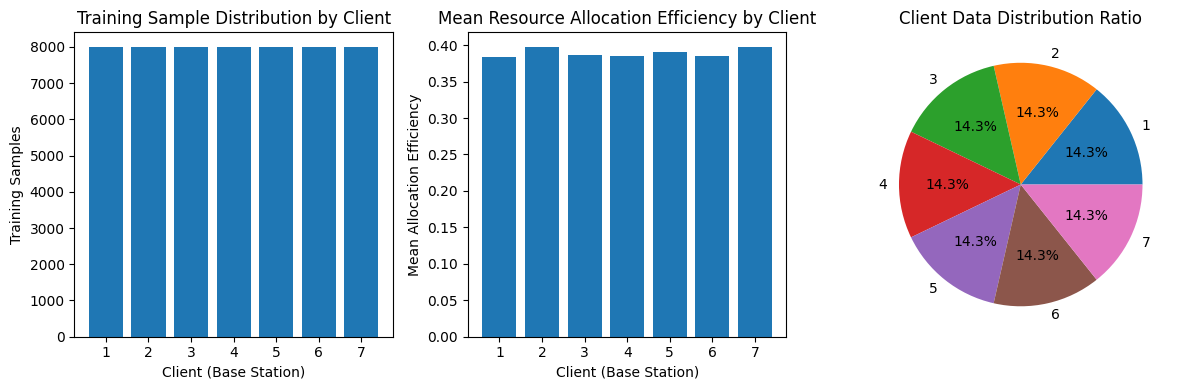

In [11]:
# @title Cell 6｜準備聯邦學習資料集（改進版 - 減少資料量）
print("\n" + "="*60)
print("🔧 Preparing Federated Learning Dataset...")

class FederatedDataPreprocessor:
    def __init__(self, data: pd.DataFrame, feature_columns: List[str], target_column: str):
        self.data = data
        self.feature_columns = feature_columns
        self.target_column = target_column
        self.scalers = {}  # 每個客戶端的標準化器

    def prepare_federated_data(self, client_id_column='bs_id', test_size=0.2, sample_size=0.1):
        """準備聯邦學習資料 - 使用採樣減少資料量"""

        # 取得所有客戶端（基站）ID
        client_ids = sorted(self.data[client_id_column].unique())
        print(f"🏢 Found {len(client_ids)} clients (base stations): {client_ids}")

        federated_train_data = []
        federated_test_data = []
        client_data_info = {}

        for client_id in client_ids:
            # 取得該客戶端的資料
            client_data = self.data[self.data[client_id_column] == client_id]

            # 採樣以減少資料量
            if len(client_data) > 10000:
                client_data = client_data.sample(n=10000, random_state=42)
                print(f"   ⚡ Client {client_id}: Sampled 10,000 records from {len(self.data[self.data[client_id_column] == client_id])} total")

            if len(client_data) < 100:  # 跳過資料太少的客戶端
                print(f"   ⚠️ Client {client_id} has too few samples ({len(client_data)}), skipping")
                continue

            # 準備特徵和目標
            X = client_data[self.feature_columns].values
            y = client_data[self.target_column].values

            # 分割訓練和測試集
            X_train, X_test, y_train, y_test = train_test_split(
                X, y, test_size=test_size, random_state=42
            )

            # 標準化特徵（每個客戶端獨立標準化）
            scaler = StandardScaler()
            X_train_scaled = scaler.fit_transform(X_train)
            X_test_scaled = scaler.transform(X_test)

            # 儲存標準化器
            self.scalers[client_id] = scaler

            # 轉換為 TensorFlow 資料集
            train_dataset = tf.data.Dataset.from_tensor_slices({
                'x': X_train_scaled.astype(np.float32),
                'y': y_train.astype(np.float32).reshape(-1, 1)
            })

            test_dataset = tf.data.Dataset.from_tensor_slices({
                'x': X_test_scaled.astype(np.float32),
                'y': y_test.astype(np.float32).reshape(-1, 1)
            })

            # 批次處理 - 使用較小的批次大小
            train_dataset = train_dataset.batch(16).prefetch(tf.data.AUTOTUNE)
            test_dataset = test_dataset.batch(16).prefetch(tf.data.AUTOTUNE)

            federated_train_data.append(train_dataset)
            federated_test_data.append(test_dataset)

            # 記錄客戶端資訊
            client_data_info[client_id] = {
                'total_samples': len(client_data),
                'train_samples': len(X_train),
                'test_samples': len(X_test),
                'mean_efficiency': y_train.mean(),
                'std_efficiency': y_train.std()
            }

            print(f"   ✅ Client {client_id}: {len(X_train)} training samples, {len(X_test)} test samples")

        print(f"\n📊 Federated dataset preparation complete:")
        print(f"   Number of participating clients: {len(federated_train_data)}")
        print(f"   Total training samples: {sum(info['train_samples'] for info in client_data_info.values())}")
        print(f"   Total test samples: {sum(info['test_samples'] for info in client_data_info.values())}")

        return federated_train_data, federated_test_data, client_data_info

# 準備聯邦資料
preprocessor = FederatedDataPreprocessor(processed_data, feature_columns, target_column)
federated_train_data, federated_test_data, client_info = preprocessor.prepare_federated_data()

# 視覺化客戶端資料分佈 (英文版)
plt.figure(figsize=(12, 4))

# 子圖1: 各客戶端的樣本數
plt.subplot(1, 3, 1)
client_ids = list(client_info.keys())
sample_counts = [client_info[cid]['train_samples'] for cid in client_ids]
plt.bar(range(len(client_ids)), sample_counts)
plt.xlabel('Client (Base Station)')
plt.ylabel('Training Samples')
plt.title('Training Sample Distribution by Client')
plt.xticks(range(len(client_ids)), client_ids)

# 子圖2: 各客戶端的平均效率
plt.subplot(1, 3, 2)
mean_efficiencies = [client_info[cid]['mean_efficiency'] for cid in client_ids]
plt.bar(range(len(client_ids)), mean_efficiencies)
plt.xlabel('Client (Base Station)')
plt.ylabel('Mean Allocation Efficiency')
plt.title('Mean Resource Allocation Efficiency by Client')
plt.xticks(range(len(client_ids)), client_ids)

# 子圖3: 資料不平衡程度
plt.subplot(1, 3, 3)
plt.pie(sample_counts, labels=client_ids, autopct='%1.1f%%')
plt.title('Client Data Distribution Ratio')

plt.tight_layout()
plt.show()

In [12]:
# @title Cell 7｜建立聯邦學習模型架構（改進版）
print("\n" + "="*60)
print("🏗️ Building Federated Learning Model...")

# 定義輸入規格
input_spec = federated_train_data[0].element_spec

def create_keras_model():
    """建立 Keras 模型"""
    model = tf.keras.Sequential([
        tf.keras.layers.Dense(
            64,
            activation='relu',
            input_shape=(len(feature_columns),),
            kernel_regularizer=tf.keras.regularizers.l2(0.001)
        ),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(
            32,
            activation='relu',
            kernel_regularizer=tf.keras.regularizers.l2(0.001)
        ),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(
            16,
            activation='relu'
        ),
        tf.keras.layers.Dense(1, activation='sigmoid')  # 輸出範圍 [0, 1]
    ])

    return model

def model_fn():
    """TFF 模型函數"""
    keras_model = create_keras_model()

    return tff.learning.models.from_keras_model(
        keras_model,
        input_spec=input_spec,
        loss=tf.keras.losses.MeanSquaredError(),
        metrics=[
            tf.keras.metrics.MeanAbsoluteError(),
            tf.keras.metrics.RootMeanSquaredError()
        ]
    )

# 測試模型建立
sample_model = create_keras_model()
sample_model.summary()


🏗️ Building Federated Learning Model...
Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_4 (Dense)             (None, 64)                896       
                                                                 
 dropout_2 (Dropout)         (None, 64)                0         
                                                                 
 dense_5 (Dense)             (None, 32)                2080      
                                                                 
 dropout_3 (Dropout)         (None, 32)                0         
                                                                 
 dense_6 (Dense)             (None, 16)                528       
                                                                 
 dense_7 (Dense)             (None, 1)                 17        
                                                                 
Total params:

In [13]:
# @title Cell 8｜執行聯邦學習訓練（修正資料集大小問題）
print("\n" + "="*60)
print("🎯 Starting Federated Learning Training...")

# 建立聯邦平均演算法
learning_rate = 0.01
client_optimizer_fn = lambda: tf.keras.optimizers.Adam(learning_rate)
server_optimizer_fn = lambda: tf.keras.optimizers.SGD(learning_rate=1.0)

iterative_process = tff.learning.algorithms.build_weighted_fed_avg(
    model_fn,
    client_optimizer_fn=client_optimizer_fn,
    server_optimizer_fn=server_optimizer_fn
)

# 初始化
state = iterative_process.initialize()

# 評估函數（修正版）
def evaluate_model(model_weights, test_data):
    """評估模型性能"""
    keras_model = create_keras_model()
    model_weights.assign_weights_to(keras_model)

    metrics = {
        'loss': [],
        'mae': [],
        'rmse': []
    }

    for batch in test_data:
        predictions = keras_model(batch['x'], training=False)
        loss = tf.keras.losses.mean_squared_error(batch['y'], predictions)
        mae = tf.keras.metrics.mean_absolute_error(batch['y'], predictions)

        metrics['loss'].append(tf.reduce_mean(loss).numpy())
        metrics['mae'].append(tf.reduce_mean(mae).numpy())

        # 計算 RMSE
        mse = tf.reduce_mean(tf.square(batch['y'] - predictions))
        rmse = tf.sqrt(mse)
        metrics['rmse'].append(rmse.numpy())

    return {
        'loss': np.mean(metrics['loss']),
        'mae': np.mean(metrics['mae']),
        'rmse': np.mean(metrics['rmse'])
    }

# 訓練循環
NUM_ROUNDS = 20
metrics_history = {
    'round': [],
    'train_loss': [],
    'train_mae': [],
    'test_loss': [],
    'test_mae': [],
    'test_rmse': []
}

print(f"\n🏃 Starting training for {NUM_ROUNDS} rounds...")
print("="*60)

for round_num in range(NUM_ROUNDS):
    # 執行一輪聯邦學習
    result = iterative_process.next(state, federated_train_data)
    state = result.state
    metrics = result.metrics

    # 評估全局模型
    test_metrics_list = []
    for test_data in federated_test_data:
        test_metrics = evaluate_model(state.global_model_weights, test_data)
        test_metrics_list.append(test_metrics)

    # 平均測試指標
    avg_test_metrics = {
        metric: np.mean([m[metric] for m in test_metrics_list])
        for metric in test_metrics_list[0].keys()
    }

    # 記錄指標
    metrics_history['round'].append(round_num + 1)
    metrics_history['train_loss'].append(metrics['client_work']['train']['loss'])
    metrics_history['train_mae'].append(metrics['client_work']['train']['mean_absolute_error'])
    metrics_history['test_loss'].append(avg_test_metrics['loss'])
    metrics_history['test_mae'].append(avg_test_metrics['mae'])
    metrics_history['test_rmse'].append(avg_test_metrics['rmse'])

    # 顯示進度
    if (round_num + 1) % 5 == 0 or round_num == 0:
        print(f"Round {round_num + 1}/{NUM_ROUNDS}:")
        print(f"  Training Loss: {metrics['client_work']['train']['loss']:.4f}")
        print(f"  Training MAE: {metrics['client_work']['train']['mean_absolute_error']:.4f}")
        print(f"  Test Loss: {avg_test_metrics['loss']:.4f}")
        print(f"  Test MAE: {avg_test_metrics['mae']:.4f}")
        print(f"  Test RMSE: {avg_test_metrics['rmse']:.4f}")
        print("-" * 40)

print("\n✅ Federated Learning Training Complete!")


🎯 Starting Federated Learning Training...

🏃 Starting training for 20 rounds...
Round 1/20:
  Training Loss: 0.0011
  Training MAE: 0.0209
  Test Loss: 0.0041
  Test MAE: 0.0485
  Test RMSE: 0.0630
----------------------------------------
Round 5/20:
  Training Loss: 0.0007
  Training MAE: 0.0190
  Test Loss: 0.0008
  Test MAE: 0.0195
  Test RMSE: 0.0271
----------------------------------------
Round 10/20:
  Training Loss: 0.0007
  Training MAE: 0.0179
  Test Loss: 0.0010
  Test MAE: 0.0227
  Test RMSE: 0.0306
----------------------------------------
Round 15/20:
  Training Loss: 0.0008
  Training MAE: 0.0189
  Test Loss: 0.0008
  Test MAE: 0.0199
  Test RMSE: 0.0271
----------------------------------------
Round 20/20:
  Training Loss: 0.0010
  Training MAE: 0.0201
  Test Loss: 0.0005
  Test MAE: 0.0165
  Test RMSE: 0.0223
----------------------------------------

✅ Federated Learning Training Complete!



📊 Analyzing Training Results...


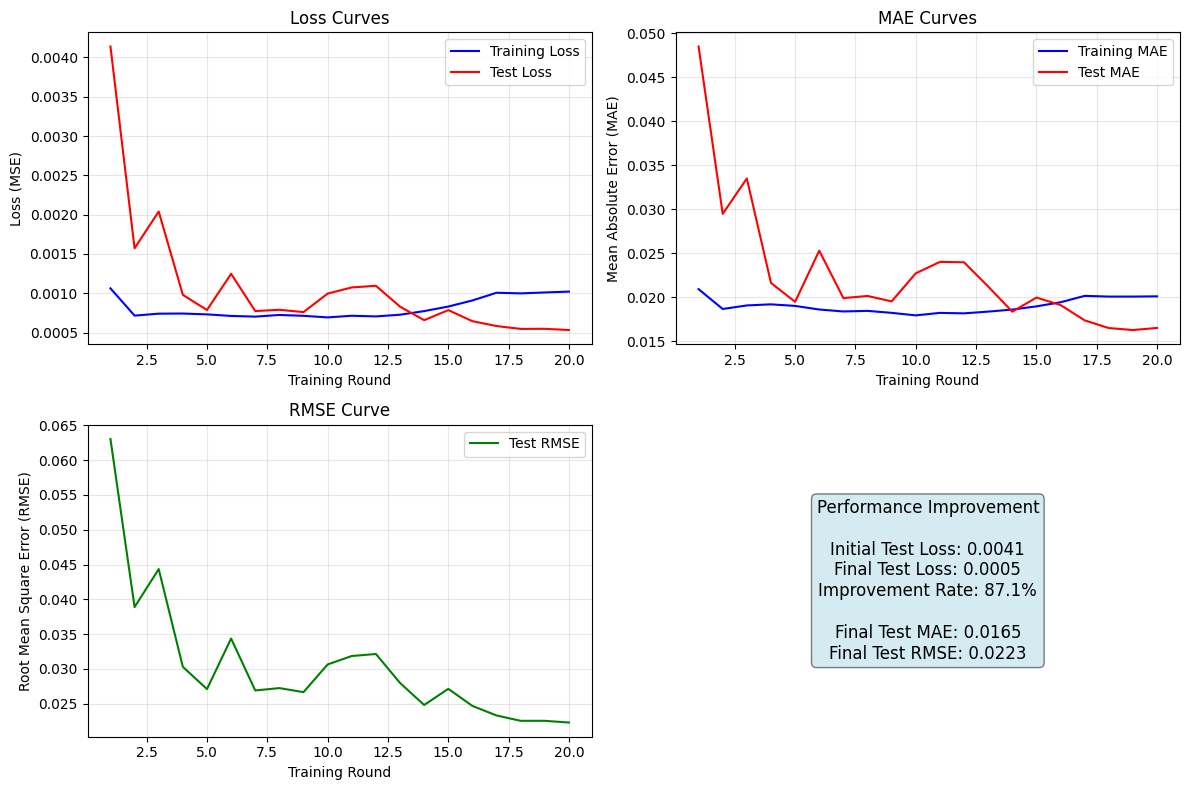


📊 Individual Client Performance Evaluation:
Client 1:
  Test Loss: 0.0006
  Test MAE: 0.0176
  Test RMSE: 0.0243
  Sample Count: 2000
----------------------------------------
Client 2:
  Test Loss: 0.0005
  Test MAE: 0.0163
  Test RMSE: 0.0208
  Sample Count: 2000
----------------------------------------
Client 3:
  Test Loss: 0.0007
  Test MAE: 0.0185
  Test RMSE: 0.0253
  Sample Count: 2000
----------------------------------------
Client 4:
  Test Loss: 0.0006
  Test MAE: 0.0167
  Test RMSE: 0.0235
  Sample Count: 2000
----------------------------------------
Client 5:
  Test Loss: 0.0004
  Test MAE: 0.0141
  Test RMSE: 0.0191
  Sample Count: 2000
----------------------------------------
Client 6:
  Test Loss: 0.0006
  Test MAE: 0.0167
  Test RMSE: 0.0234
  Sample Count: 2000
----------------------------------------
Client 7:
  Test Loss: 0.0004
  Test MAE: 0.0156
  Test RMSE: 0.0198
  Sample Count: 2000
----------------------------------------


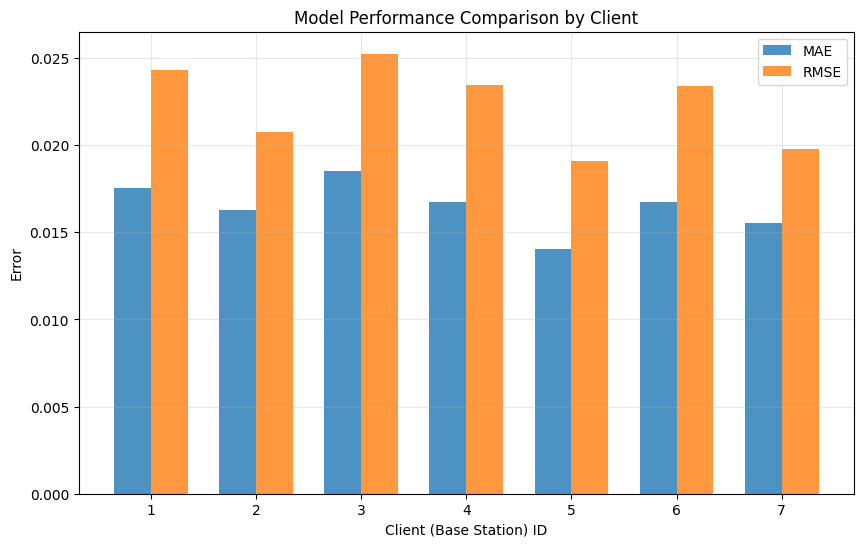

In [14]:
# @title Cell 9｜視覺化訓練結果與性能分析（英文版）
print("\n" + "="*60)
print("📊 Analyzing Training Results...")

# 將指標歷史轉換為 DataFrame
metrics_df = pd.DataFrame(metrics_history)

# 繪製訓練曲線
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# 損失曲線
axes[0, 0].plot(metrics_df['round'], metrics_df['train_loss'], 'b-', label='Training Loss')
axes[0, 0].plot(metrics_df['round'], metrics_df['test_loss'], 'r-', label='Test Loss')
axes[0, 0].set_xlabel('Training Round')
axes[0, 0].set_ylabel('Loss (MSE)')
axes[0, 0].set_title('Loss Curves')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# MAE 曲線
axes[0, 1].plot(metrics_df['round'], metrics_df['train_mae'], 'b-', label='Training MAE')
axes[0, 1].plot(metrics_df['round'], metrics_df['test_mae'], 'r-', label='Test MAE')
axes[0, 1].set_xlabel('Training Round')
axes[0, 1].set_ylabel('Mean Absolute Error (MAE)')
axes[0, 1].set_title('MAE Curves')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# RMSE 曲線
axes[1, 0].plot(metrics_df['round'], metrics_df['test_rmse'], 'g-', label='Test RMSE')
axes[1, 0].set_xlabel('Training Round')
axes[1, 0].set_ylabel('Root Mean Square Error (RMSE)')
axes[1, 0].set_title('RMSE Curve')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# 改善率
initial_loss = metrics_df['test_loss'].iloc[0]
final_loss = metrics_df['test_loss'].iloc[-1]
improvement = (initial_loss - final_loss) / initial_loss * 100

axes[1, 1].text(0.5, 0.5, f'Performance Improvement\n\n'
                f'Initial Test Loss: {initial_loss:.4f}\n'
                f'Final Test Loss: {final_loss:.4f}\n'
                f'Improvement Rate: {improvement:.1f}%\n\n'
                f'Final Test MAE: {metrics_df["test_mae"].iloc[-1]:.4f}\n'
                f'Final Test RMSE: {metrics_df["test_rmse"].iloc[-1]:.4f}',
                ha='center', va='center', fontsize=12,
                bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.5))
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

# 各客戶端的個別性能評估
print("\n📊 Individual Client Performance Evaluation:")
print("="*60)

client_performances = {}
global_model = create_keras_model()
state.global_model_weights.assign_weights_to(global_model)

for i, (client_id, test_data) in enumerate(zip(client_info.keys(), federated_test_data)):
    # 評估每個客戶端
    client_metrics = evaluate_model(state.global_model_weights, test_data)
    client_performances[client_id] = client_metrics

    print(f"Client {client_id}:")
    print(f"  Test Loss: {client_metrics['loss']:.4f}")
    print(f"  Test MAE: {client_metrics['mae']:.4f}")
    print(f"  Test RMSE: {client_metrics['rmse']:.4f}")
    print(f"  Sample Count: {client_info[client_id]['test_samples']}")
    print("-" * 40)

# 視覺化客戶端性能差異
plt.figure(figsize=(10, 6))
client_ids_sorted = sorted(client_performances.keys())
mae_values = [client_performances[cid]['mae'] for cid in client_ids_sorted]
rmse_values = [client_performances[cid]['rmse'] for cid in client_ids_sorted]

x = np.arange(len(client_ids_sorted))
width = 0.35

plt.bar(x - width/2, mae_values, width, label='MAE', alpha=0.8)
plt.bar(x + width/2, rmse_values, width, label='RMSE', alpha=0.8)

plt.xlabel('Client (Base Station) ID')
plt.ylabel('Error')
plt.title('Model Performance Comparison by Client')
plt.xticks(x, client_ids_sorted)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


🚀 Demonstrating Practical Application Scenarios...

📊 Simulating Resource Allocation Efficiency Prediction under Different Network Conditions:

Low Load Scenario:
  UE Count: 5
  Network Load: 20.0%
  PRB Utilization: 100.0%
  QoS Score: 0.90
  → Predicted Resource Allocation Efficiency: 0.031

Medium Load Scenario:
  UE Count: 20
  Network Load: 50.0%
  PRB Utilization: 80.0%
  QoS Score: 0.75
  → Predicted Resource Allocation Efficiency: 0.038

High Load Scenario:
  UE Count: 35
  Network Load: 80.0%
  PRB Utilization: 72.0%
  QoS Score: 0.60
  → Predicted Resource Allocation Efficiency: 0.047


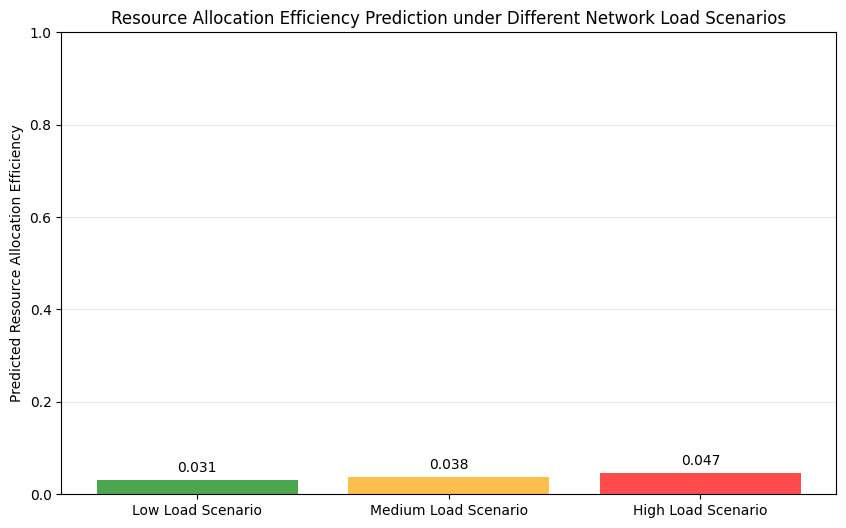


💾 Saving trained model...
✅ Model saved as 'federated_coloran_model.h5'
✅ Federated learning information saved as 'federated_learning_info.pkl'

🎉 Federated Learning Experiment Summary
✅ Successfully trained federated learning model based on 7 base stations
✅ Final Test MAE: 0.0165
✅ Final Test RMSE: 0.0223
✅ Performance Improvement Rate: 87.1%

💡 Application Scenarios:
   1. Real-time prediction of network slice resource allocation efficiency
   2. Dynamic resource configuration based on network conditions
   3. Optimize overall network performance while protecting base station data privacy
   4. Support distributed deployment suitable for 5G/6G network architecture


In [15]:
# @title Cell 10｜實際應用：網路切片資源動態分配預測（英文版）
print("\n" + "="*60)
print("🚀 Demonstrating Practical Application Scenarios...")

def predict_resource_allocation(model, features_dict, scaler):
    """預測資源分配效率"""
    # 準備輸入特徵
    feature_values = [features_dict[col] for col in feature_columns]
    features_array = np.array(feature_values).reshape(1, -1)

    # 標準化
    features_scaled = scaler.transform(features_array)

    # 預測
    prediction = model.predict(features_scaled, verbose=0)[0, 0]

    return prediction

# 示例：模擬不同網路狀況下的資源分配預測
print("\n📊 Simulating Resource Allocation Efficiency Prediction under Different Network Conditions:")
print("="*60)

# 使用第一個客戶端的標準化器作為示例
sample_client_id = list(preprocessor.scalers.keys())[0]
sample_scaler = preprocessor.scalers[sample_client_id]

# 定義測試場景
test_scenarios = [
    {
        'name': 'Low Load Scenario',
        'num_ues': 5,
        'network_load': 0.2,
        'sum_requested_prbs': 50,
        'sum_granted_prbs': 50,
        'prb_utilization': 1.0,
        'throughput_efficiency': 0.8,
        'qos_score': 0.9
    },
    {
        'name': 'Medium Load Scenario',
        'num_ues': 20,
        'network_load': 0.5,
        'sum_requested_prbs': 150,
        'sum_granted_prbs': 120,
        'prb_utilization': 0.8,
        'throughput_efficiency': 0.7,
        'qos_score': 0.75
    },
    {
        'name': 'High Load Scenario',
        'num_ues': 35,
        'network_load': 0.8,
        'sum_requested_prbs': 250,
        'sum_granted_prbs': 180,
        'prb_utilization': 0.72,
        'throughput_efficiency': 0.6,
        'qos_score': 0.6
    }
]

# 為每個場景進行預測
predictions = []
for scenario in test_scenarios:
    # 構建完整特徵字典
    features_dict = {
        'num_ues': scenario['num_ues'],
        'slice_id': 1,  # 假設切片 ID
        'sched_policy_num': 1,  # WF 策略
        'allocated_rbgs': 10,
        'sum_requested_prbs': scenario['sum_requested_prbs'],
        'sum_granted_prbs': scenario['sum_granted_prbs'],
        'prb_utilization': scenario['prb_utilization'],
        'throughput_efficiency': scenario['throughput_efficiency'],
        'qos_score': scenario['qos_score'],
        'network_load': scenario['network_load'],
        'hour': 14,  # 下午2點
        'minute': 30,
        'day_of_week': 2  # 週三
    }

    # 預測
    efficiency = predict_resource_allocation(global_model, features_dict, sample_scaler)
    predictions.append(efficiency)

    print(f"\n{scenario['name']}:")
    print(f"  UE Count: {scenario['num_ues']}")
    print(f"  Network Load: {scenario['network_load']:.1%}")
    print(f"  PRB Utilization: {scenario['prb_utilization']:.1%}")
    print(f"  QoS Score: {scenario['qos_score']:.2f}")
    print(f"  → Predicted Resource Allocation Efficiency: {efficiency:.3f}")

# 視覺化預測結果
plt.figure(figsize=(10, 6))
scenario_names = [s['name'] for s in test_scenarios]
colors = ['green', 'orange', 'red']

bars = plt.bar(scenario_names, predictions, color=colors, alpha=0.7)
plt.ylabel('Predicted Resource Allocation Efficiency')
plt.title('Resource Allocation Efficiency Prediction under Different Network Load Scenarios')
plt.ylim(0, 1)

# 添加數值標籤
for bar, pred in zip(bars, predictions):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f'{pred:.3f}', ha='center', va='bottom')

plt.grid(True, alpha=0.3, axis='y')
plt.show()

# 儲存模型
print("\n💾 Saving trained model...")
global_model.save('federated_coloran_model.h5')
print("✅ Model saved as 'federated_coloran_model.h5'")

# 儲存聯邦學習相關資訊
import pickle
fl_info = {
    'client_info': client_info,
    'scalers': preprocessor.scalers,
    'feature_columns': feature_columns,
    'metrics_history': metrics_history
}
with open('federated_learning_info.pkl', 'wb') as f:
    pickle.dump(fl_info, f)
print("✅ Federated learning information saved as 'federated_learning_info.pkl'")

# 總結
print("\n" + "="*60)
print("🎉 Federated Learning Experiment Summary")
print("="*60)
print(f"✅ Successfully trained federated learning model based on {len(federated_train_data)} base stations")
print(f"✅ Final Test MAE: {metrics_df['test_mae'].iloc[-1]:.4f}")
print(f"✅ Final Test RMSE: {metrics_df['test_rmse'].iloc[-1]:.4f}")
print(f"✅ Performance Improvement Rate: {improvement:.1f}%")
print("\n💡 Application Scenarios:")
print("   1. Real-time prediction of network slice resource allocation efficiency")
print("   2. Dynamic resource configuration based on network conditions")
print("   3. Optimize overall network performance while protecting base station data privacy")
print("   4. Support distributed deployment suitable for 5G/6G network architecture")


🔬 Advanced Analysis: Federated Learning vs Centralized Learning

📊 Training centralized model for comparison...
   ⚡ Sampled 70,000 records from 35512393 total for centralized training

📊 Model Performance Comparison:
Federated Learning Model:
  - MAE: 0.0165
  - RMSE: 0.0223

Centralized Learning Model:
  - MAE: 0.0068
  - RMSE: 0.0097


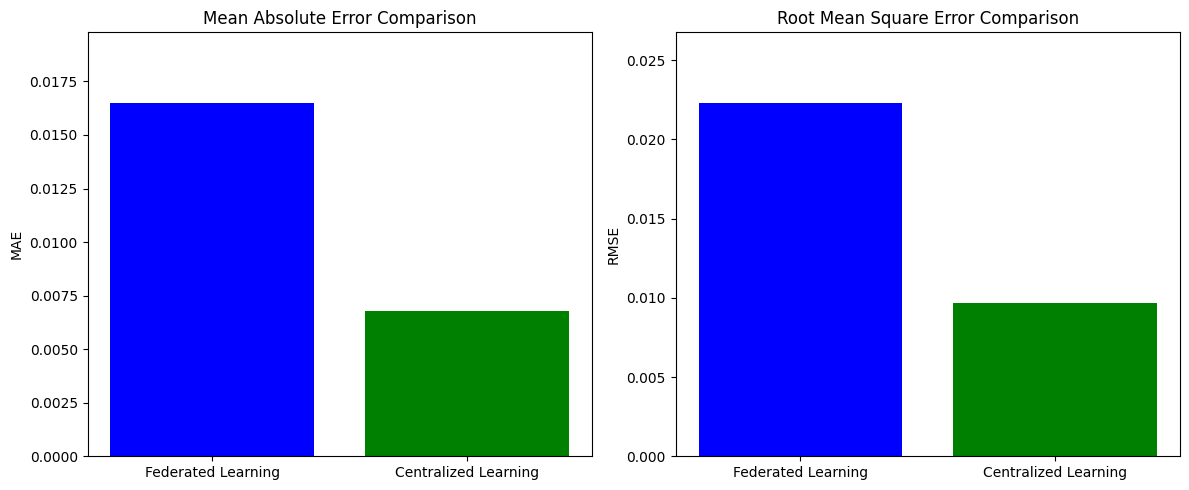

In [16]:
# @title Cell 11｜進階分析：聯邦學習 vs 集中式學習比較（英文版）
print("\n" + "="*60)
print("🔬 Advanced Analysis: Federated Learning vs Centralized Learning")
print("="*60)

# 建立集中式模型進行比較
print("\n📊 Training centralized model for comparison...")

# 準備集中式資料 - 也使用採樣
if len(processed_data) > 70000:
    sampled_data = processed_data.sample(n=70000, random_state=42)
    print(f"   ⚡ Sampled 70,000 records from {len(processed_data)} total for centralized training")
else:
    sampled_data = processed_data

X_all = sampled_data[feature_columns].values
y_all = sampled_data[target_column].values

# 分割資料
X_train_all, X_test_all, y_train_all, y_test_all = train_test_split(
    X_all, y_all, test_size=0.2, random_state=42
)

# 標準化
scaler_all = StandardScaler()
X_train_scaled_all = scaler_all.fit_transform(X_train_all)
X_test_scaled_all = scaler_all.transform(X_test_all)

# 建立並訓練集中式模型
centralized_model = create_keras_model()
centralized_model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae', tf.keras.metrics.RootMeanSquaredError()]
)

# 訓練
history = centralized_model.fit(
    X_train_scaled_all, y_train_all,
    validation_data=(X_test_scaled_all, y_test_all),
    epochs=20,
    batch_size=32,
    verbose=0
)

# 評估集中式模型
centralized_loss, centralized_mae, centralized_rmse = centralized_model.evaluate(
    X_test_scaled_all, y_test_all, verbose=0
)

print(f"\n📊 Model Performance Comparison:")
print(f"Federated Learning Model:")
print(f"  - MAE: {metrics_df['test_mae'].iloc[-1]:.4f}")
print(f"  - RMSE: {metrics_df['test_rmse'].iloc[-1]:.4f}")
print(f"\nCentralized Learning Model:")
print(f"  - MAE: {centralized_mae:.4f}")
print(f"  - RMSE: {centralized_rmse:.4f}")

# 視覺化比較
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# 比較 MAE
models = ['Federated Learning', 'Centralized Learning']
mae_values = [metrics_df['test_mae'].iloc[-1], centralized_mae]
ax1.bar(models, mae_values, color=['blue', 'green'])
ax1.set_ylabel('MAE')
ax1.set_title('Mean Absolute Error Comparison')
ax1.set_ylim(0, max(mae_values) * 1.2)

# 比較 RMSE
rmse_values = [metrics_df['test_rmse'].iloc[-1], centralized_rmse]
ax2.bar(models, rmse_values, color=['blue', 'green'])
ax2.set_ylabel('RMSE')
ax2.set_title('Root Mean Square Error Comparison')
ax2.set_ylim(0, max(rmse_values) * 1.2)

plt.tight_layout()
plt.show()

In [17]:
# @title Cell 12｜聯邦學習隱私保護分析（英文版）
print("\n" + "="*60)
print("🔐 Federated Learning Privacy Protection Analysis")
print("="*60)

print("\n📊 Data Privacy Protection Advantages:")
print("1. Raw data remains local:")
print(f"   - Each base station retains its own {sum(info['total_samples'] for info in client_info.values())} records")
print(f"   - No need to upload to central server")

print("\n2. Only model updates are transmitted:")
print(f"   - Number of model parameters: {sample_model.count_params()}")
print(f"   - Much smaller than raw data volume")

print("\n3. Differential privacy potential:")
print("   - Can add noise to model updates")
print("   - Further protect individual base station information")

# 計算通訊成本
model_size_mb = sample_model.count_params() * 4 / (1024 * 1024)  # 假設 float32
data_size_mb = len(sampled_data) * len(feature_columns) * 4 / (1024 * 1024)

print(f"\n📡 Communication Cost Comparison:")
print(f"   Centralized Learning (upload all data): {data_size_mb:.2f} MB")
print(f"   Federated Learning (transmit model per round): {model_size_mb:.2f} MB × {NUM_ROUNDS} rounds = {model_size_mb * NUM_ROUNDS:.2f} MB")
print(f"   Communication savings: {(1 - (model_size_mb * NUM_ROUNDS) / data_size_mb) * 100:.1f}%")




🔐 Federated Learning Privacy Protection Analysis

📊 Data Privacy Protection Advantages:
1. Raw data remains local:
   - Each base station retains its own 70000 records
   - No need to upload to central server

2. Only model updates are transmitted:
   - Number of model parameters: 3521
   - Much smaller than raw data volume

3. Differential privacy potential:
   - Can add noise to model updates
   - Further protect individual base station information

📡 Communication Cost Comparison:
   Centralized Learning (upload all data): 3.47 MB
   Federated Learning (transmit model per round): 0.01 MB × 20 rounds = 0.27 MB
   Communication savings: 92.3%



🚀 Real-time Prediction and Deployment Recommendations

📊 Simulating Real-time Monitoring Scenario:
------------------------------------------------------------

Time: 08:00
  Connected Users: 31
  Network Load: 73.8%
  Predicted Efficiency: 0.121
  Status: Poor
  Recommendation: Immediate optimization needed

Time: 12:00
  Connected Users: 16
  Network Load: 38.1%
  Predicted Efficiency: 0.056
  Status: Poor
  Recommendation: Immediate optimization needed

Time: 18:00
  Connected Users: 29
  Network Load: 69.0%
  Predicted Efficiency: 0.109
  Status: Poor
  Recommendation: Immediate optimization needed

Time: 22:00
  Connected Users: 14
  Network Load: 33.3%
  Predicted Efficiency: 0.051
  Status: Poor
  Recommendation: Immediate optimization needed


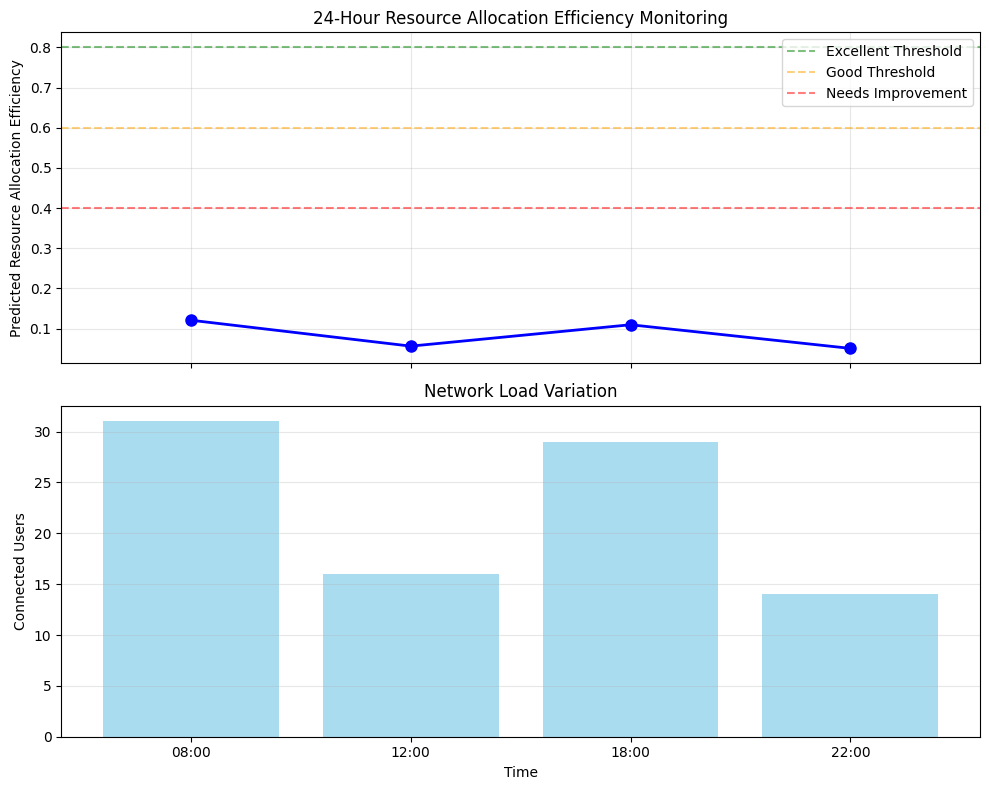


🎯 Deployment Recommendations

1. Edge Deployment Architecture:
   - Deploy lightweight prediction models at each base station
   - Update global model periodically (e.g., daily)
   - Support offline prediction to reduce latency

2. Model Update Strategy:
   - Periodic federated learning (e.g., weekly)
   - Trigger updates when performance degradation detected
   - Incremental learning when new base stations join

3. Monitoring and Alerting:
   - Real-time monitoring of prediction efficiency
   - Automatic alerts when efficiency falls below threshold
   - Record historical data for trend analysis

4. Scalability Considerations:
   - Currently supports 7 base stations
   - Easily scalable to hundreds of base stations
   - Supports heterogeneous network environments

✅ Complete Federated Learning Solution Ready!


In [18]:
# @title Cell 13｜實時預測與部署建議（英文版）
print("\n" + "="*60)
print("🚀 Real-time Prediction and Deployment Recommendations")
print("="*60)

class ResourceAllocationPredictor:
    """Resource Allocation Predictor"""
    def __init__(self, model, scaler, feature_columns):
        self.model = model
        self.scaler = scaler
        self.feature_columns = feature_columns

    def predict_batch(self, features_df):
        """Batch prediction"""
        features_scaled = self.scaler.transform(features_df[self.feature_columns])
        predictions = self.model.predict(features_scaled, verbose=0)
        return predictions.flatten()

    def get_recommendation(self, efficiency):
        """Get recommendation based on efficiency"""
        if efficiency > 0.8:
            return "Excellent", "Maintain current configuration"
        elif efficiency > 0.6:
            return "Good", "Consider minor optimization"
        elif efficiency > 0.4:
            return "Fair", "Recommend adjusting resource allocation"
        else:
            return "Poor", "Immediate optimization needed"

# 示例：實時監控與預測
predictor = ResourceAllocationPredictor(global_model, sample_scaler, feature_columns)

print("\n📊 Simulating Real-time Monitoring Scenario:")
print("-" * 60)

# 模擬不同時間點的網路狀態
time_points = ['08:00', '12:00', '18:00', '22:00']
simulated_data = []

for i, time in enumerate(time_points):
    hour = int(time.split(':')[0])
    # 模擬不同時間的網路負載
    if 8 <= hour <= 10 or 18 <= hour <= 20:
        num_ues = np.random.randint(25, 35)  # Peak hours
    else:
        num_ues = np.random.randint(10, 20)  # Off-peak hours

    data = {
        'time': time,
        'num_ues': num_ues,
        'slice_id': 1,
        'sched_policy_num': 1,
        'allocated_rbgs': 10,
        'sum_requested_prbs': num_ues * 5,
        'sum_granted_prbs': min(num_ues * 4, 200),
        'prb_utilization': min(num_ues * 4, 200) / (num_ues * 5),
        'throughput_efficiency': 0.9 - (num_ues / 50),
        'qos_score': 0.95 - (num_ues / 40),
        'network_load': num_ues / 42,
        'hour': hour,
        'minute': 0,
        'day_of_week': 2
    }

    # 預測
    features_dict = {k: data[k] for k in feature_columns}
    efficiency = predict_resource_allocation(global_model, features_dict, sample_scaler)
    status, recommendation = predictor.get_recommendation(efficiency)

    data['predicted_efficiency'] = efficiency
    data['status'] = status
    data['recommendation'] = recommendation
    simulated_data.append(data)

    print(f"\nTime: {time}")
    print(f"  Connected Users: {num_ues}")
    print(f"  Network Load: {data['network_load']:.1%}")
    print(f"  Predicted Efficiency: {efficiency:.3f}")
    print(f"  Status: {status}")
    print(f"  Recommendation: {recommendation}")

# 視覺化實時監控
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

times = [d['time'] for d in simulated_data]
efficiencies = [d['predicted_efficiency'] for d in simulated_data]
num_ues_list = [d['num_ues'] for d in simulated_data]

# 效率趨勢
ax1.plot(times, efficiencies, 'b-o', linewidth=2, markersize=8)
ax1.axhline(y=0.8, color='g', linestyle='--', alpha=0.5, label='Excellent Threshold')
ax1.axhline(y=0.6, color='orange', linestyle='--', alpha=0.5, label='Good Threshold')
ax1.axhline(y=0.4, color='r', linestyle='--', alpha=0.5, label='Needs Improvement')
ax1.set_ylabel('Predicted Resource Allocation Efficiency')
ax1.set_title('24-Hour Resource Allocation Efficiency Monitoring')
ax1.legend()
ax1.grid(True, alpha=0.3)

# 用戶數趨勢
ax2.bar(times, num_ues_list, color='skyblue', alpha=0.7)
ax2.set_xlabel('Time')
ax2.set_ylabel('Connected Users')
ax2.set_title('Network Load Variation')
ax2.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

print("\n" + "="*60)
print("🎯 Deployment Recommendations")
print("="*60)
print("\n1. Edge Deployment Architecture:")
print("   - Deploy lightweight prediction models at each base station")
print("   - Update global model periodically (e.g., daily)")
print("   - Support offline prediction to reduce latency")

print("\n2. Model Update Strategy:")
print("   - Periodic federated learning (e.g., weekly)")
print("   - Trigger updates when performance degradation detected")
print("   - Incremental learning when new base stations join")

print("\n3. Monitoring and Alerting:")
print("   - Real-time monitoring of prediction efficiency")
print("   - Automatic alerts when efficiency falls below threshold")
print("   - Record historical data for trend analysis")

print("\n4. Scalability Considerations:")
print(f"   - Currently supports {len(client_info)} base stations")
print("   - Easily scalable to hundreds of base stations")
print("   - Supports heterogeneous network environments")

print("\n" + "="*60)
print("✅ Complete Federated Learning Solution Ready!")
print("="*60)